## 路由、请求处理、响应处理

 ### 知识总览

 | 知识点 | 功能说明                                               |
 |--------|----------------------------------------------------|
 | 路由定义 | 使用 `@app.get/post/put/patch/delete` 装饰器定义 RESTful 接口 |
 | async def vs def | 理解异步路由与同步路由的区别及适用场景                                |
 | 路径参数 | 通过 `{参数名}` 捕获 URL 路径中的变量，Path()约束                  |
 | 查询参数 | 通过 URL 中`？`后的字符串传递参数，Query()约束                     |
 | 请求体 | 用 Pydantic 模型定义 JSON 请求体，自动解析和校验                   |
 | Form 表单 | 接收 `application/x-www-form-urlencoded` 格式的表单数据     |
 | 文件上传 | 使用 `UploadFile` 处理文件上传，支持读取内容和获取元信息                |
 | 响应模型 | 通过 `response_model` 精确控制返回数据结构，过滤敏感字段              |
 | 状态码控制 | 自定义 HTTP 状态码，使用 `JSONResponse` 返回不同响应              |

一个 URL 请求包含
- 请求方法 -> GET/POST/PUT/PATCH/DELETE
- 路径参数(Path) -> 函数参数，URL{name}
- 查询参数(Query) -> 函数参数，URL?key=value
- 请求体(Field) -> Pydantic 模型 / Body(), JSON Body
- 请求头 -> Header()
- Cookie -> Cookie()
- 文件 -> File() / UploadFile, multipart body
- 表单 -> Form, multipart/form-data

一个请求的响应包含
- 状态码
- 响应头
- 响应体

### 1. 路由定义


使用 `@app.get/post/put/patch/delete` 装饰器定义 RESTful 接口

| 方法 | 语义 | 幂等 | 安全 | AI 应用典型场景 |
|------|------|------|------|-----------------|
| **GET** | 读取资源 | ✅ | ✅ | 查询对话历史、获取知识库文档列表、检索配置 |
| **POST** | 创建资源 / 触发处理 | ❌ | ❌ | 发起 LLM 推理、上传文档、创建 Agent 会话 |
| **PUT** | 全量替换资源 | ✅ | ❌ | 替换完整 Prompt 模板、覆盖知识库配置 |
| **PATCH** | 部分更新资源 | ❌ | ❌ | 修改 temperature、调整检索参数 |
| **DELETE** | 删除资源 | ✅ | ❌ | 删除对话记录、移除知识库文档 |

> 幂等性： 同一请求执行一次和执行多次效果相同。这对 AI 服务尤其重要——重试一个非幂等请求可能导致重复推理计费

### 2. 路径参数与查询参数
- 路径参数(Path) -> 函数参数，URL{name}
- 查询参数(Query) -> 函数参数，URL?key=value

**注意路径顺序**：固定路径（如 `/todos/me`）必须定义在动态路径（如 `/todos/{todo_id}`）之前，否则 `me` 会被错误地当作 `todo_id` 的值。


| 对比维度   | 路径参数                                | 查询参数                            |
|--------|-------------------------------------|---------------------------------|
| 定义方式   | 路由路径中用 `{}` 定义，如 `/items/{item_id}` | 函数中非路径参数自动识别                    |
| 接收方式   | 函数同名参数自动接收                          | URL `?key=value` 传递，如 `?skip=0` |
| 是否必填   | 始终必填                                | 有默认值/`None` 可选，无默认值必填           |
| 参数验证   | `Path()`         | `Query()`              |
| 示例 URL | `/items/42`                         | `/items?skip=0&limit=10`        |
| 应用场景   | 标识特定资源                              | 过滤、分页、排序、搜索关键词、功能开关             |


In [ ]:
from enum import Enum
from fastapi import FastAPI, Path, Query

app = FastAPI()

class TodoStatus(str, Enum):
    pending = "pending"
    in_progress = "in_progress"
    completed = "completed"

@app.get("/todos/{todo_id}")          # 路由声明：{todo_id} 是路径参数占位符
async def get_todo(
        todo_id: int = Path(..., ge=1),                # 路径参数，Path(...) 表示必填；ge=1 表示 ≥1，校验失败返回 422
        priority: int = Query(None, ge=1, le=5),       # 查询参数；Query约束，默认 None 即选填；ge/le 限定 1~5
        status: TodoStatus = Query(TodoStatus.pending, description="任务状态"),  # 枚举查询参数，默认 pending；取值只能是枚举成员，否则 422
        tags: list[str] = Query(None, description="标签列表，可重复传参"),          # 列表查询参数 list[str] 支持 ?tags=a&tags=b 重复传参；默认 None 表示选填
    ):
    return {"todo_id": todo_id, "priority": priority, "status": status, "tags": tags}  # 【重要】返回 dict，FastAPI 自动序列化（Enum 自动转字符串值）

# 【重要】调用示例：路径参数 + 查询参数 + 枚举 + 列表 混合传参
# http://localhost:8000/todos/6?priority=3
# http://localhost:8000/todos/6?priority=3&status=completed&tags=work&tags=urgent

if __name__ == "__main__":
    import uvicorn
    uvicorn.run("main:app", host="127.0.0.1", port=8000, reload=True)  # 【重要】"main:app" 中的 main 必须与文件名 main.py 一致，否则启动失败

INFO:     Will watch for changes in these directories: ['E:\\Agent\\llm_application_development_tutorial\\02_FastAPI_tutorial\\02-路由与请求']
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)
INFO:     Started reloader process [28800] using WatchFiles


### 3 请求体
- Pydantic 模型 → 请求体
- 主要住现在 POST/PUT/PATCH，不是 URL 的一部分，大小不受 URL 长度限制
- 请求体参数验证：Field

In [ ]:
from pydantic import BaseModel
from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware

app = FastAPI()
# 允许跨域请求（解决 Apifox/浏览器调用时的 CORS 拦截问题）
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],      # 允许所有来源（学习阶段先放开，生产环境建议指定域名）
    allow_credentials=True,
    allow_methods=["*"],      # 允许所有 HTTP 方法
    allow_headers=["*"],      # 允许所有请求头
)

class Todo(BaseModel):
    title: str
    description: float
    priority: int

class User(BaseModel):
    username: str
    full_name: str | None = None

@app.put("/todos/{todo_id}")
async def update_todo(todo_id: int, todo: Todo, user: User):
    return {"todo_id": todo_id, "todo": todo, "user": user}

if __name__ == "__main__":
    import uvicorn
    uvicorn.run("main:app", host="127.0.0.1", port=8000, reload=True)

INFO:     Will watch for changes in these directories: ['E:\\Agent\\llm_application_development_tutorial\\02_FastAPI_tutorial\\02-路由与请求']
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)
INFO:     Started reloader process [56824] using WatchFiles


https://hoppscotch.io/

方法：POST

URL：`http://localhost:8000/todos/7` 路径里的 `7` 就是 `todo_id`

请求体 → 内容类型 → application/json
```
{
  "todo": {"title": "Buy milk", "description": "2 liters", "priority": 1},
  "user": {"username": "dave", "full_name": "Dave Grohl"}
}
```

### 4. 响应处理
- 方式一：直接 `return` 数据，比如 Python对象 `dict`、`list`等，FastAPI会`自动`将其放入`JSONResponse`，并做好 `JSON 序列化` 后返回
- 方式二：声明响应模型，`@app.post("path", response_model=xxx, status_code=xxx)`
- 方式三：使用 `Response` 对象， 会导致`response_model`失效；举例：使用 `JSONResponse` 显示声明，当需要自`定义状态码`、`响应头`，同时又想返回 JSON 数据时



无论用哪种写法，一次请求变成 HTTP 响应都要经过下面几步：
```
路由函数返回值
      ↓
[分支] 是 Response 实例吗？ ──是──→ 原样发送（几乎不插手）
      │否
      ↓
jsonable_encoder() 序列化（dict/list/模型/dataclass/datetime/UUID/Enum…）
      ↓
包装成 JSONResponse（默认），写入 status_code、headers、cookies
      ↓
Starlette/Uvicorn 写出字节流

```

响应状态码的语义速查
- `2xx 成功`：默认 200；创建资源用 201；无内容返回用 204（不可有 body）。
- `3xx 重定向`：302 用于临时跳转；304 不可有 body。、
- `4xx 客户端错误`：404 资源不存在，400 通用客户端错误，422 FastAPI 自动用于请求体校验失败。
- `5xx 服务端错误`：response_model 输出校验失败时返回 500，排错方向应指向业务返回值与模型声明不符。

#### 方式一：直接 return dict，默认走得就是 JSONResponse

In [5]:
# 【推荐】 方式一：直接 return dict，默认走得就是 JSONResponse
from fastapi import FastAPI
app = FastAPI()
@app.get("/items/{item_id}")
def read_item(item_id: int):
    return {"item_id": item_id, "name": "Foo"}

#### 方式二：声明响应模型


In [ ]:
# 【推荐】方式二：声明响应模型 response_model + status_code 或 response_model + raise HTTPException
from pydantic import BaseModel
from fastapi import FastAPI
app = FastAPI()
class UserIn(BaseModel):
    username: str
    email: str
    password: str
class UserOut(BaseModel):
    id: int
    username: str
    email: str
@app.post("/users", response_model=UserOut, status_code=201)
async def create_user(user: UserIn):
    saved_user = {"id": 1, **user.model_dump()} # 模拟保存到数据库
    return saved_user  # password 字段会被 response_model 自动过滤

自定义异常响应处理

In [ ]:
from fastapi import HTTPException, status
app = FastAPI()

@app.get("/items/{item_id}")
def read_item(item_id: int):
    if item_id  < 6:
        return {"item_id": item_id}
    else:
        raise HTTPException(status_code=404, detail="Item not found")

#### 方式三：使用 Response 对象

```
starlette.responses.Response          ← 基类（所有响应的共同祖先）
├── JSONResponse                      ← JSON （默认）
├── HTMLResponse                      ← HTML
├── PlainTextResponse                 ← 纯文本
├── RedirectResponse                  ← 重定向
├── FileResponse                      ← 文件
├── StreamingResponse                 ← 流式响应
└── ...
```

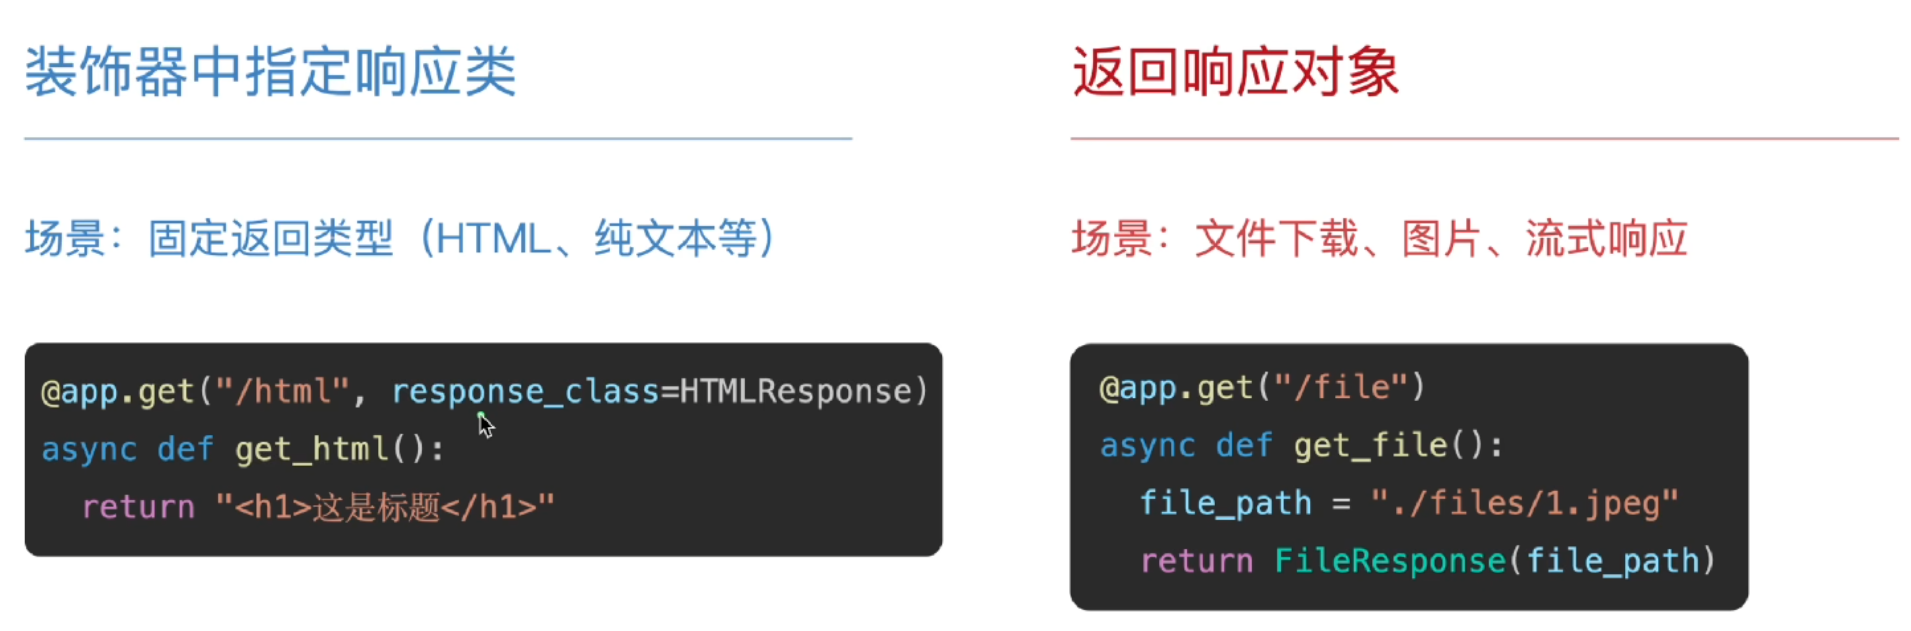

JSONResponse

In [ ]:
# 显示声明 JSONResponse (response_model会失效)，当需要改 status_code，headers和media_type 的时候用
from fastapi.responses import JSONResponse
from fastapi import FastAPI
app = FastAPI()
@app.post("/json")
def get_json(name: str):
    content = {"name": name, "created": True}
    return JSONResponse(
        content=content,                     # 【必填】字典，如果是 Pydantic 模型，必须先转换为字典
        status_code=201,                     # 自定义状态码
        headers={"X-Request-Id": "abc-123"}, # 自定义响应头
        # media_type="application/json",     # 默认就是 application/json
        # background=None,                   # BackgroundTasks
    )

HTMLResponse

In [ ]:
from fastapi.responses import HTMLResponse
from fastapi import FastAPI
app = FastAPI()
@app.post("/html", response_class=HTMLResponse)
def get_html():
    return "<h1>这是 HTML 响应：一级标题</h1>"

FileResponse

In [ ]:
"""
    FileResponse是FastAPI提供的专门用于高效返回文件内容(如图片、PDF、Excel、音视频等)的响应类。
    它能够智能处理文件路径、媒体类型推断、范围请求和缓存头部，是服务静态文件的推荐方式。
"""
from fastapi.responses import FileResponse
from fastapi import FastAPI
app = FastAPI()
@app.get("/file")
def get_file():
    file_path = "main.py"
    return FileResponse(file_path)

StreamingResponse

普通响应有 `Content-Length`，客户端知道何时结束。流式响应无法预知总长度，使用 `Transfer-Encoding: chunked`（HTTP/1.1）逐块发送。

```
from fastapi import FastAPI
from fastapi.responses import StreamingResponse

app = FastAPI()

async def gen():
    for token in llm_stream():
        yield f"data: {token}\n\n"

@app.get("/stream")
async def stream():
    return StreamingResponse(gen(), media_type="text/event-stream")
```